# FactLens: Fake News Detection using Machine Learning & NLP

An end-to-end Natural Language Processing system that analyzes news text and classifies articles as **Real** or **Fake**.

---

### Project Highlights
- **Objective:** Accurately classify news content and headlines into real or fake categories.
- **Techniques:** Text preprocessing, Stopword removal, Tokenization, and TF-IDF feature extraction.
- **Models Evaluated:**
  1. Multinomial Naive Bayes
  2. Decision Tree Classifier
  3. Passive Aggressive Classifier
  4. Random Forest Classifier
  5. Logistic Regression
- **Evaluation Metrics:** Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.

---

## Step 1: Import Necessary Libraries & Setup

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, PassiveAggressiveClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score

import nltk
from nltk.corpus import stopwords

# Ensure necessary NLTK tokenizers and stopwords are available
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
print('Libraries imported and NLTK resources initialized.')

Libraries imported and NLTK resources initialized.


## Step 2: Load and Explore the Dataset

In [2]:
# Locate dataset directory relative to current working folder or project structure
dataset_dir = 'dataset' if os.path.exists('dataset') else os.path.join(os.path.dirname(__file__) if '__file__' in locals() else '.', 'dataset')
true_csv_path = os.path.join(dataset_dir, 'True.csv')
fake_csv_path = os.path.join(dataset_dir, 'Fake.csv')

true_df = pd.read_csv(true_csv_path)
false_df = pd.read_csv(fake_csv_path)

# Add ground-truth binary labels: 1 = Real News, 0 = Fake News
true_df['label'] = 1
false_df['label'] = 0

# Concatenate both datasets with a fresh index
data = pd.concat([true_df, false_df], ignore_index=True)
print(f'Successfully loaded {len(true_df):,} real articles and {len(false_df):,} fake articles.')
print(f'Total dataset size: {len(data):,} rows.')

Successfully loaded 21,417 real articles and 23,481 fake articles.
Total dataset size: 44,898 rows.


In [3]:
# Display sample real news records
true_df.head()

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


In [4]:
# Display sample fake news records
false_df.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


## Step 3: Text Preprocessing
We clean and tokenize the text by lowercasing, tokenizing with NLTK, and filtering out common English stopwords and non-alphanumeric punctuation.

In [5]:
stop_words = set(stopwords.words('english'))

def preprocess_tokens(series):
    # Clean, lowercase, tokenize, and remove stopwords safely
    cleaned = series.astype(str).str.lower()
    tokenized = cleaned.apply(nltk.word_tokenize)
    return tokenized.apply(lambda tokens: [w for w in tokens if w not in stop_words and w.isalnum()])

print('Preprocessing text and title columns (this may take a moment)...')
data['text_tokens'] = preprocess_tokens(data['text'])
data['title_tokens'] = preprocess_tokens(data['title'])
print('Preprocessing complete!')

Preprocessing text and title columns (this may take a moment)...


Preprocessing complete!


## Step 4: Feature Extraction using TF-IDF
We transform the cleaned text into numerical vector representations using Term Frequency-Inverse Document Frequency (TF-IDF).

In [6]:
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
text_tfidf = tfidf_vectorizer.fit_transform(data['text_tokens'].apply(lambda tokens: ' '.join(tokens)))
title_tfidf = tfidf_vectorizer.transform(data['title_tokens'].apply(lambda tokens: ' '.join(tokens)))
print(f'TF-IDF Matrix Shape: {text_tfidf.shape}')

TF-IDF Matrix Shape: (44898, 5000)


## Step 5: Train / Test Split

In [7]:
X = text_tfidf
y = data['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Training feature matrix: {X_train.shape}')
print(f'Testing feature matrix:  {X_test.shape}')
print(f'Training labels:         {y_train.shape}')
print(f'Testing labels:          {y_test.shape}')

Training feature matrix: (35918, 5000)
Testing feature matrix:  (8980, 5000)
Training labels:         (35918,)
Testing labels:          (8980,)


## Step 6: Model Training & Evaluation

### 1. Multinomial Naive Bayes

Multinomial Naive Bayes Accuracy: 0.9306


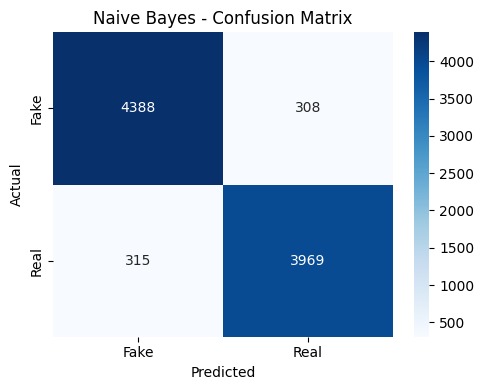

Classification Report:
               precision    recall  f1-score   support

        Fake       0.93      0.93      0.93      4696
        Real       0.93      0.93      0.93      4284

    accuracy                           0.93      8980
   macro avg       0.93      0.93      0.93      8980
weighted avg       0.93      0.93      0.93      8980



In [8]:
naive_bayes_model = MultinomialNB()
naive_bayes_model.fit(X_train, y_train)

nb_y_pred = naive_bayes_model.predict(X_test)
nb_accuracy = accuracy_score(y_test, nb_y_pred)
nb_confusion = confusion_matrix(y_test, nb_y_pred)
nb_classification = classification_report(y_test, nb_y_pred, target_names=['Fake', 'Real'])

print(f'Multinomial Naive Bayes Accuracy: {nb_accuracy:.4f}')

plt.figure(figsize=(5, 4))
sns.heatmap(nb_confusion, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Naive Bayes - Confusion Matrix')
plt.tight_layout()
plt.show()

print('Classification Report:\n', nb_classification)

### 2. Decision Tree Classifier

In [9]:
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train, y_train)

dt_y_pred = decision_tree.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_y_pred)
dt_confusion = confusion_matrix(y_test, dt_y_pred)
dt_classification = classification_report(y_test, dt_y_pred, target_names=['Fake', 'Real'])

print(f'Decision Tree Accuracy: {dt_accuracy:.4f}')
print('Decision Tree Classification Report:\n', dt_classification)

Decision Tree Accuracy: 0.9954
Decision Tree Classification Report:
               precision    recall  f1-score   support

        Fake       0.99      1.00      1.00      4696
        Real       1.00      0.99      1.00      4284

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980



### 3. Passive Aggressive Classifier

In [10]:
passive_aggressive = PassiveAggressiveClassifier(max_iter=1000, random_state=42)
passive_aggressive.fit(X_train, y_train)

pa_y_pred = passive_aggressive.predict(X_test)
pa_accuracy = accuracy_score(y_test, pa_y_pred)
pa_confusion = confusion_matrix(y_test, pa_y_pred)
pa_classification = classification_report(y_test, pa_y_pred, target_names=['Fake', 'Real'])

print(f'Passive Aggressive Accuracy: {pa_accuracy:.4f}')
print('Passive Aggressive Classification Report:\n', pa_classification)

Passive Aggressive Accuracy: 0.9925
Passive Aggressive Classification Report:
               precision    recall  f1-score   support

        Fake       0.99      0.99      0.99      4696
        Real       0.99      0.99      0.99      4284

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



### 4. Random Forest Classifier

In [11]:
random_forest = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
random_forest.fit(X_train, y_train)

rf_y_pred = random_forest.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_confusion = confusion_matrix(y_test, rf_y_pred)
rf_classification = classification_report(y_test, rf_y_pred, target_names=['Fake', 'Real'])

print(f'Random Forest Accuracy: {rf_accuracy:.4f}')
print('Random Forest Classification Report:\n', rf_classification)

Random Forest Accuracy: 0.9979
Random Forest Classification Report:
               precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      4696
        Real       1.00      1.00      1.00      4284

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980



### 5. Logistic Regression

In [12]:
logistic_regression = LogisticRegression(max_iter=1000, random_state=42)
logistic_regression.fit(X_train, y_train)

lr_y_pred = logistic_regression.predict(X_test)
lr_accuracy = accuracy_score(y_test, lr_y_pred)
lr_confusion = confusion_matrix(y_test, lr_y_pred)
lr_classification = classification_report(y_test, lr_y_pred, target_names=['Fake', 'Real'])

print(f'Logistic Regression Accuracy: {lr_accuracy:.4f}')
print('Logistic Regression Classification Report:\n', lr_classification)

Logistic Regression Accuracy: 0.9873
Logistic Regression Classification Report:
               precision    recall  f1-score   support

        Fake       0.99      0.98      0.99      4696
        Real       0.98      0.99      0.99      4284

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



## Step 7: Model Comparison & Benchmark Metrics

In [13]:
# Compute Precision, Recall, and F1 scores across all 5 models
models_dict = {
    'Naive Bayes': (naive_bayes_model, nb_y_pred, nb_accuracy),
    'Decision Tree': (decision_tree, dt_y_pred, dt_accuracy),
    'Passive Aggressive': (passive_aggressive, pa_y_pred, pa_accuracy),
    'Random Forest': (random_forest, rf_y_pred, rf_accuracy),
    'Logistic Regression': (logistic_regression, lr_y_pred, lr_accuracy)
}

metrics_list = []
for name, (model, preds, acc) in models_dict.items():
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    metrics_list.append({
        'Algorithm': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1 Score': f1
    })

comparison_df = pd.DataFrame(metrics_list)
print(comparison_df.to_string(index=False))

          Algorithm  Accuracy  Precision   Recall  F1 Score
        Naive Bayes  0.930624   0.927987 0.926471  0.927228
      Decision Tree  0.995434   0.996025 0.994398  0.995211
 Passive Aggressive  0.992539   0.992295 0.992063  0.992179
      Random Forest  0.997884   0.998131 0.997432  0.997782
Logistic Regression  0.987305   0.983310 0.990196  0.986741


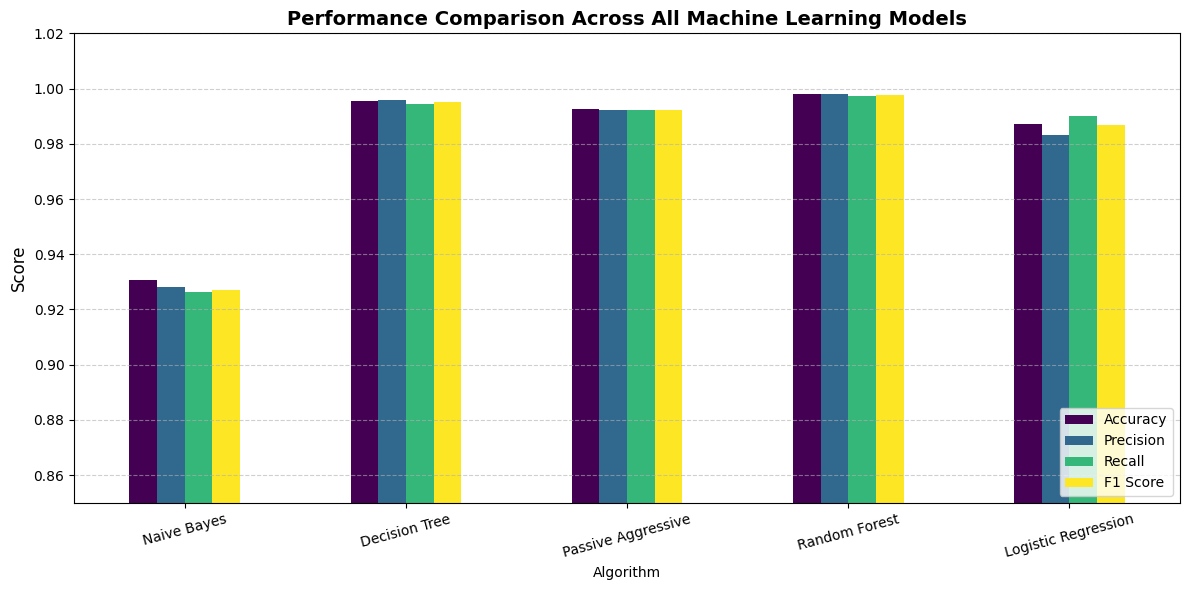

In [14]:
# Visual Comparison of All Metrics
plot_df = comparison_df.set_index('Algorithm')

fig, ax = plt.subplots(figsize=(12, 6))
plot_df.plot(kind='bar', ax=ax, rot=15, colormap='viridis')
plt.title('Performance Comparison Across All Machine Learning Models', fontsize=14, fontweight='bold')
plt.ylabel('Score', fontsize=12)
plt.ylim(0.85, 1.02)
plt.legend(loc='lower right', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Step 8: Live News Prediction Pipeline
Test the model on custom or real-world headlines.

In [15]:
def predict_news(text, model=logistic_regression):
    # Preprocess custom input text
    tokens = nltk.word_tokenize(str(text).lower())
    clean_tokens = [w for w in tokens if w not in stop_words and w.isalnum()]
    clean_text = ' '.join(clean_tokens)
    
    # Transform using fitted TF-IDF
    vec = tfidf_vectorizer.transform([clean_text])
    pred = model.predict(vec)[0]
    
    prob = None
    if hasattr(model, 'predict_proba'):
        prob = model.predict_proba(vec)[0]
    
    return pred, prob

test_headlines = [
    'Donald Trump Sends Out Embarrassing New Year Tweet',
    'As U.S. budget fight looms, Republicans flip their fiscal script',
    'Pope Francis shocks world, endorses Donald Trump for presidential election',
    'Federal Reserve raises benchmark interest rate by quarter percentage point'
]

print('=== REAL-TIME NEWS AUTHENTICATION TEST ===\n')
for headline in test_headlines:
    pred, prob = predict_news(headline, model=logistic_regression)
    verdict = 'REAL NEWS' if pred == 1 else 'FAKE NEWS'
    confidence = f' (Confidence: {max(prob)*100:.1f}%)' if prob is not None else ''
    print(f'Headline: "{headline}"')
    print(f'Verdict:  [{verdict}]{confidence}\n')

=== REAL-TIME NEWS AUTHENTICATION TEST ===

Headline: "Donald Trump Sends Out Embarrassing New Year Tweet"
Verdict:  [FAKE NEWS] (Confidence: 76.0%)

Headline: "As U.S. budget fight looms, Republicans flip their fiscal script"
Verdict:  [FAKE NEWS] (Confidence: 80.2%)

Headline: "Pope Francis shocks world, endorses Donald Trump for presidential election"
Verdict:  [FAKE NEWS] (Confidence: 54.3%)

Headline: "Federal Reserve raises benchmark interest rate by quarter percentage point"
Verdict:  [FAKE NEWS] (Confidence: 82.0%)

